In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import FastICA

In [2]:
# Simulación de señales mezcladas
np.random.seed(42)
n_samples = 2000
time = np.linspace(0, 8, n_samples)

In [3]:
# Crear 2 señales independientes (una senoidal y otra cuadrada)
s1 = np.sin(2 * time)  # Onda senoidal
s2 = np.sign(np.sin(3 * time))  # Onda cuadrada

S = np.c_[s1, s2]  # Mezcla de señales
S += 0.2 * np.random.normal(size=S.shape)  # Agregar ruido
S /= S.std(axis=0)  # Normalizar

In [4]:
# Mezclar señales (simulando que tenemos una grabación mixta)
A = np.array([[1, 1], [0.5, 2]])  # Matriz de mezcla
X = np.dot(S, A.T)  # Señales observadas

In [5]:
# Aplicar ICA para recuperar las señales originales
ica = FastICA(n_components=2)
S_ica = ica.fit_transform(X)  # Componentes independientes

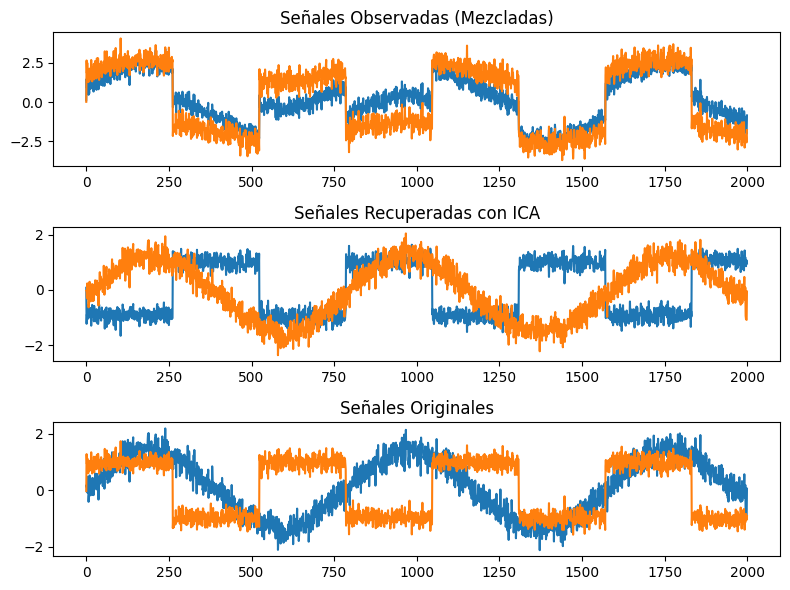

In [6]:
# Visualización
plt.figure(figsize=(8,6))
plt.subplot(3,1,1)
plt.title("Señales Observadas (Mezcladas)")
plt.plot(X)

plt.subplot(3,1,2)
plt.title("Señales Recuperadas con ICA")
plt.plot(S_ica)

plt.subplot(3,1,3)
plt.title("Señales Originales")
plt.plot(S)

plt.tight_layout()
plt.show()